# 01 – Phân tích thăm dò dữ liệu (EDA)

In [1]:
# Chạy trên Google Colab: kết nối Drive và chuyển vào thư mục notebooks của dự án (máy cá nhân thì bỏ qua)
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/DM_Nhom3_Final/notebooks')  # sửa nếu để thư mục dự án ở chỗ khác
except ImportError:
    pass
print(os.getcwd())

/home/claude/DM_Nhom3_Final/notebooks


In [2]:
import sys, warnings
sys.path.append('../src'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from style import setup, save, vn, BLUE, ORANGE, AQUA, GRAY, INK, INK2
setup(); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
DATA = '../data/'

## 1. Đọc dữ liệu (7 bảng)
`causal_data` (trưng bày / quảng cáo theo tuần) không dùng cho 4 bước chính nên không đọc ở đây.

In [3]:
trans = pd.read_csv(DATA+'transaction_data.csv')
prod  = pd.read_csv(DATA+'product.csv')
demo  = pd.read_csv(DATA+'hh_demographic.csv')
cdesc = pd.read_csv(DATA+'campaign_desc.csv')
ctab  = pd.read_csv(DATA+'campaign_table.csv')
coup  = pd.read_csv(DATA+'coupon.csv')
red   = pd.read_csv(DATA+'coupon_redempt.csv')
tables = {'transaction_data':trans,'product':prod,'hh_demographic':demo,'campaign_desc':cdesc,
          'campaign_table':ctab,'coupon':coup,'coupon_redempt':red}
for n,d in tables.items(): print(f'{n:18s} {d.shape}'); 
trans.head()

transaction_data   (2595732, 12)
product            (92353, 7)
hh_demographic     (801, 8)
campaign_desc      (30, 4)
campaign_table     (7208, 3)
coupon             (124548, 3)
coupon_redempt     (2318, 4)


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


## 2. Chất lượng dữ liệu
Đếm ô trống, dòng trùng, giá trị âm/bằng 0 và khóa không khớp giữa các bảng.

In [4]:
q = pd.DataFrame({n: {'Số dòng': len(d), 'Số cột': d.shape[1], 'Ô trống': int(d.isna().sum().sum()),
                      'Dòng trùng': int(d.duplicated().sum())} for n,d in tables.items()}).T
q

,Số dòng,Số cột,Ô trống,Dòng trùng
transaction_data,2595732,12,0,0
product,92353,7,0,0
hh_demographic,801,8,0,0
campaign_desc,30,4,0,0
campaign_table,7208,3,0,0
coupon,124548,3,0,5164
coupon_redempt,2318,4,0,0


In [5]:
chk = {
 'SALES_VALUE <= 0': int((trans.SALES_VALUE<=0).sum()),
 'QUANTITY = 0': int((trans.QUANTITY==0).sum()),
 'QUANTITY > 100': int((trans.QUANTITY>100).sum()),
 'RETAIL_DISC > 0 (sai dấu)': int((trans.RETAIL_DISC>0).sum()),
 'COUPON_DISC != 0': int((trans.COUPON_DISC!=0).sum()),
 'PRODUCT_ID không có trong product': int((~trans.PRODUCT_ID.isin(prod.PRODUCT_ID)).sum()),
 'Hộ dùng coupon nhưng không nhận chiến dịch': int((~red.household_key.isin(ctab.household_key)).sum()),
}
print('Quy mô:', trans.household_key.nunique(), 'hộ |', trans.BASKET_ID.nunique(), 'giỏ |',
      trans.PRODUCT_ID.nunique(), 'sản phẩm |', trans.STORE_ID.nunique(), 'cửa hàng | DAY',
      trans.DAY.min(), '-', trans.DAY.max(), '| WEEK', trans.WEEK_NO.min(), '-', trans.WEEK_NO.max())
pd.Series(chk, name='Số dòng')

Quy mô: 2500 hộ | 276484 giỏ | 92339 sản phẩm | 582 cửa hàng | DAY 1 - 711 | WEEK 1 - 102


SALES_VALUE <= 0                              18850
QUANTITY = 0                                  14466
QUANTITY > 100                                23136
RETAIL_DISC > 0 (sai dấu)                        36
COUPON_DISC != 0                              36422
PRODUCT_ID không có trong product                 0
Hộ dùng coupon nhưng không nhận chiến dịch        0
Name: Số dòng, dtype: int64

In [6]:
# QUANTITY rất lớn tập trung ở department nào?
big = trans[trans.QUANTITY>100].merge(prod[['PRODUCT_ID','DEPARTMENT']], on='PRODUCT_ID')
big.DEPARTMENT.value_counts().head(5)

DEPARTMENT
KIOSK-GAS          20267
MISC SALES TRAN     2868
PRODUCE                1
Name: count, dtype: int64

## 3. Thống kê mô tả các biến số

In [7]:
m = trans.merge(prod, on='PRODUCT_ID', how='left')
basket = m.groupby('BASKET_ID').agg(household_key=('household_key','first'), DAY=('DAY','first'),
            value=('SALES_VALUE','sum'), n_items=('PRODUCT_ID','count'), n_comm=('COMMODITY_DESC','nunique'))
hh = trans.groupby('household_key').agg(spend=('SALES_VALUE','sum'), n_baskets=('BASKET_ID','nunique'),
            first_day=('DAY','min'), last_day=('DAY','max'))
hh['weeks'] = (hh.last_day - hh.first_day)/7 + 1
hh['weekly_spend'] = hh.spend / hh.weeks
def desc(s):
    return pd.Series({'Trung bình':s.mean(),'Độ lệch chuẩn':s.std(),'Nhỏ nhất':s.min(),'Q1':s.quantile(.25),
        'Trung vị':s.median(),'Q3':s.quantile(.75),'Lớn nhất':s.max(),'Skewness':stats.skew(s),'Kurtosis':stats.kurtosis(s)})
desc_tbl = pd.DataFrame({
  'SALES_VALUE / dòng ($)': desc(trans.SALES_VALUE), 'QUANTITY / dòng': desc(trans.QUANTITY),
  'Giá trị giỏ ($)': desc(basket.value), 'Số sản phẩm / giỏ': desc(basket.n_items),
  'Chi tiêu / hộ ($)': desc(hh.spend), 'Số giỏ / hộ': desc(hh.n_baskets)}).T.round(2)
desc_tbl.to_csv('../outputs/bang_thong_ke_mo_ta.csv'); desc_tbl

,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Q1,Trung vị,Q3,Lớn nhất,Skewness,Kurtosis
SALES_VALUE / dòng ($),3.10,4.18,0.00,1.29,2.00,3.49,840.00,15.91,1346.93
QUANTITY / dòng,100.43,1153.44,0.00,1.00,1.00,1.00,89638.00,13.64,228.12
Giá trị giỏ ($),29.14,36.10,0.00,6.96,17.07,36.28,961.49,3.01,15.23
Số sản phẩm / giỏ,9.39,12.28,1.00,2.00,5.00,12.00,168.00,2.73,10.33
Chi tiêu / hộ ($),3222.99,3349.03,8.17,970.74,2157.75,4413.32,38319.79,2.41,9.98
Số giỏ / hộ,110.59,115.67,1.00,39.00,79.00,142.25,1300.00,3.37,19.87


In [8]:
# Ngoại lai theo IQR cho giá trị giỏ
q1,q3 = basket.value.quantile([.25,.75]); iqr=q3-q1; hi=q3+1.5*iqr
print(f'Ngưỡng trên IQR giá trị giỏ = {hi:.2f}$, số giỏ vượt ngưỡng = {(basket.value>hi).sum()} ({(basket.value>hi).mean():.1%})')

Ngưỡng trên IQR giá trị giỏ = 80.26$, số giỏ vượt ngưỡng = 22228 (8.0%)


### Hình 1 – Phân bố giá trị giỏ, chi tiêu hộ và kích thước giỏ
Các biến đều lệch phải mạnh nên trục ngang dùng thang log.

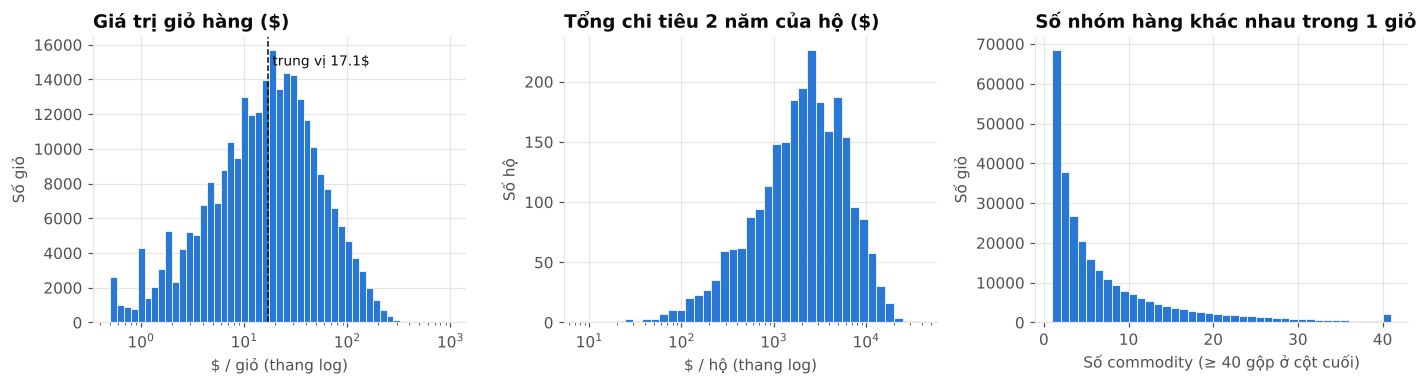

In [9]:
fig, ax = plt.subplots(1,3, figsize=(13,3.6))
bins = np.logspace(np.log10(0.5), np.log10(basket.value.max()), 50)
ax[0].hist(basket.value.clip(lower=0.5), bins=bins, color=BLUE, edgecolor='white', linewidth=0.5); ax[0].set_xscale('log')
ax[0].axvline(basket.value.median(), color=INK, ls='--', lw=1); ax[0].text(basket.value.median()*1.1, ax[0].get_ylim()[1]*0.9, f'trung vị {basket.value.median():.1f}$', color=INK, fontsize=9)
ax[0].set(title='Giá trị giỏ hàng ($)', xlabel='$ / giỏ (thang log)', ylabel='Số giỏ')
ax[1].hist(hh.spend, bins=np.logspace(np.log10(hh.spend.min()), np.log10(hh.spend.max()), 40), color=BLUE, edgecolor='white', linewidth=0.5); ax[1].set_xscale('log')
ax[1].set(title='Tổng chi tiêu 2 năm của hộ ($)', xlabel='$ / hộ (thang log)', ylabel='Số hộ')
ax[2].hist(basket.n_comm.clip(upper=40), bins=range(1,42), color=BLUE, edgecolor='white', linewidth=0.5)
ax[2].set(title='Số nhóm hàng khác nhau trong 1 giỏ', xlabel='Số commodity (≥ 40 gộp ở cột cuối)', ylabel='Số giỏ')
plt.tight_layout(); save(fig, 'H1_phan_bo_gio_va_ho')

## 4. Theo thời gian

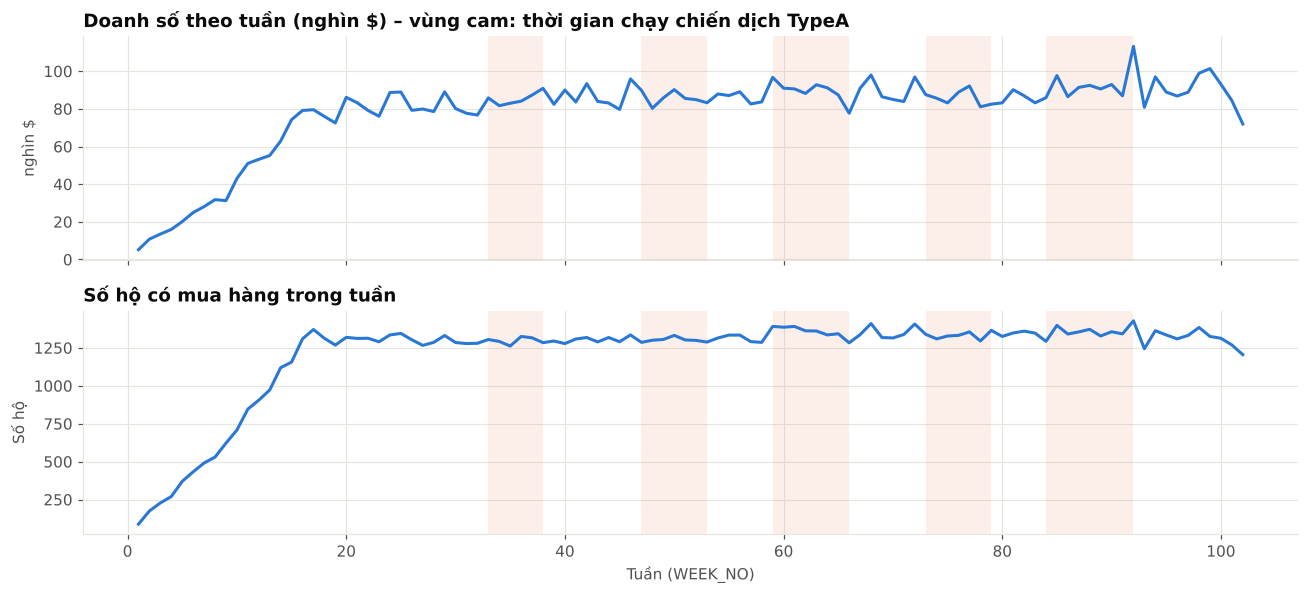

Doanh số TB tuần 1-15 vs 16-102: 34747 86624


In [10]:
wk = trans.groupby('WEEK_NO').agg(sales=('SALES_VALUE','sum'), baskets=('BASKET_ID','nunique'), hh=('household_key','nunique'))
cd = cdesc.copy(); cd['w0']=cd.START_DAY//7+1; cd['w1']=cd.END_DAY//7+1
fig, ax = plt.subplots(2,1, figsize=(12,5.5), sharex=True)
for _,r in cd[cd.DESCRIPTION=='TypeA'].iterrows():
    for a in ax: a.axvspan(r.w0, r.w1, color=ORANGE, alpha=0.10, lw=0)
ax[0].plot(wk.index, wk.sales/1000, color=BLUE, lw=2); ax[0].set(title='Doanh số theo tuần (nghìn $) – vùng cam: thời gian chạy chiến dịch TypeA', ylabel='nghìn $')
ax[1].plot(wk.index, wk.hh, color=BLUE, lw=2); ax[1].set(title='Số hộ có mua hàng trong tuần', ylabel='Số hộ', xlabel='Tuần (WEEK_NO)')
plt.tight_layout(); save(fig, 'H2_doanh_so_theo_tuan')
print('Doanh số TB tuần 1-15 vs 16-102:', round(wk.sales[:15].mean()), round(wk.sales[15:].mean()))

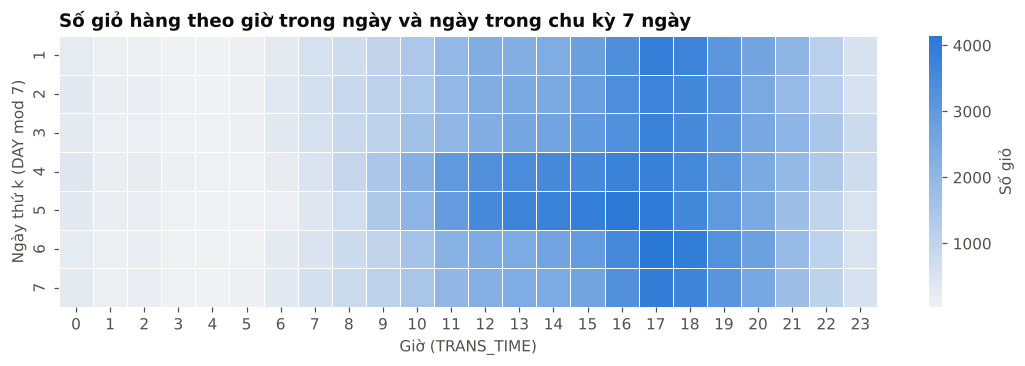

Giờ cao điểm: 17 h; tỷ trọng 15h-19h: 0.44


In [11]:
# Thời điểm mua: chu kỳ 7 ngày (DAY mod 7, không biết thứ thật vì dữ liệu ẩn danh) × giờ
tt = trans.drop_duplicates('BASKET_ID')[['DAY','TRANS_TIME']].copy()
tt['d7'] = (tt.DAY-1)%7+1; tt['hour'] = tt.TRANS_TIME//100
hm = tt.pivot_table(index='d7', columns='hour', values='DAY', aggfunc='count').fillna(0)
fig, ax = plt.subplots(figsize=(12,3.2))
sns.heatmap(hm, cmap=sns.light_palette(BLUE, as_cmap=True), cbar_kws={'label':'Số giỏ'}, ax=ax, linewidths=0.5, linecolor='white')
ax.set(title='Số giỏ hàng theo giờ trong ngày và ngày trong chu kỳ 7 ngày', xlabel='Giờ (TRANS_TIME)', ylabel='Ngày thứ k (DAY mod 7)')
save(fig, 'H3_heatmap_gio_mua')
print('Giờ cao điểm:', hm.sum().idxmax(), 'h; tỷ trọng 15h-19h:', round(hm.loc[:,15:19].values.sum()/hm.values.sum(),3))

## 5. Sản phẩm

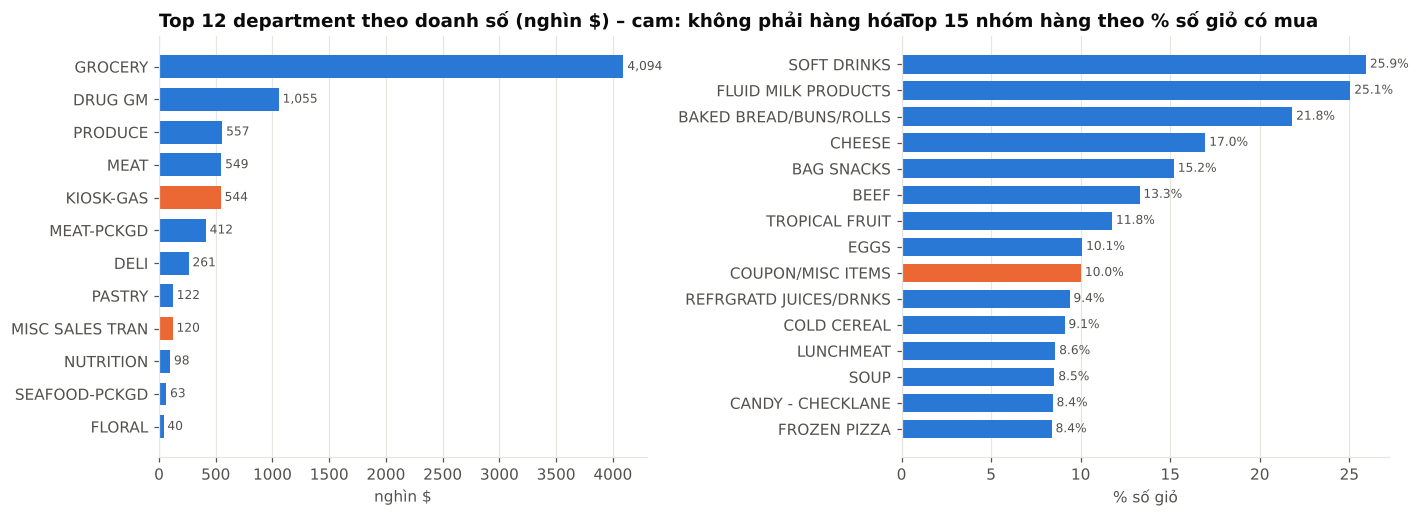

Tỷ trọng doanh số GROCERY: 0.508 | KIOSK-GAS: 0.068


In [12]:
dep = m.groupby('DEPARTMENT').SALES_VALUE.sum().sort_values(ascending=False)
comm_b = m.drop_duplicates(['BASKET_ID','COMMODITY_DESC']).COMMODITY_DESC.value_counts()/m.BASKET_ID.nunique()
fig, ax = plt.subplots(1,2, figsize=(13,4.8))
d = dep.head(12)[::-1]/1000; ax[0].barh(d.index, d.values, color=[ORANGE if i in ('KIOSK-GAS','MISC SALES TRAN') else BLUE for i in d.index], height=0.7)
ax[0].set(title='Top 12 department theo doanh số (nghìn $) – cam: không phải hàng hóa', xlabel='nghìn $'); ax[0].grid(axis='y', visible=False)
for y,v in enumerate(d.values): ax[0].text(v, y, f' {v:,.0f}', va='center', fontsize=8, color=INK2)
c = comm_b.head(15)[::-1]*100; ax[1].barh(c.index, c.values, color=[ORANGE if i=='COUPON/MISC ITEMS' else BLUE for i in c.index], height=0.7)
ax[1].set(title='Top 15 nhóm hàng theo % số giỏ có mua', xlabel='% số giỏ'); ax[1].grid(axis='y', visible=False)
for y,v in enumerate(c.values): ax[1].text(v, y, f' {v:.1f}%', va='center', fontsize=8, color=INK2)
plt.tight_layout(); save(fig, 'H4_top_department_commodity')
print('Tỷ trọng doanh số GROCERY:', round(dep['GROCERY']/dep.sum(),3), '| KIOSK-GAS:', round(dep['KIOSK-GAS']/dep.sum(),3))

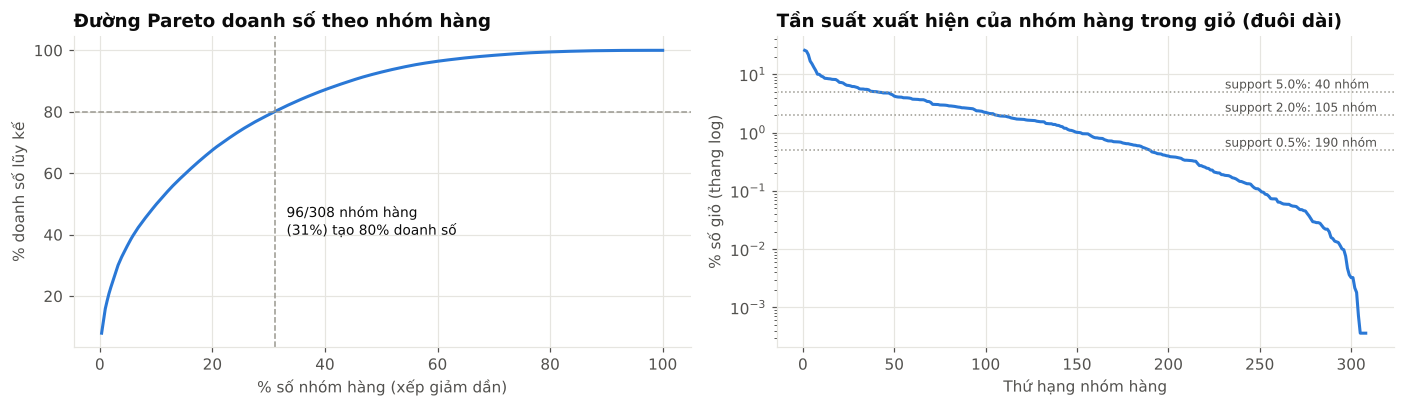

Private label: tỷ trọng doanh số 0.278


In [13]:
cs = m.groupby('COMMODITY_DESC').SALES_VALUE.sum().sort_values(ascending=False)
cum = cs.cumsum()/cs.sum(); n80 = int((cum<0.8).sum()+1)
brand = m.groupby('BRAND').SALES_VALUE.agg(['sum','count']); brand['share_sales']=brand['sum']/brand['sum'].sum()
fig, ax = plt.subplots(1,2, figsize=(13,3.8))
ax[0].plot(np.arange(1,len(cum)+1)/len(cum)*100, cum.values*100, color=BLUE, lw=2)
ax[0].axhline(80, color=GRAY, ls='--', lw=1); ax[0].axvline(n80/len(cum)*100, color=GRAY, ls='--', lw=1)
ax[0].text(n80/len(cum)*100+2, 40, f'{n80}/{len(cum)} nhóm hàng\n({n80/len(cum):.0%}) tạo 80% doanh số', color=INK, fontsize=9)
ax[0].set(title='Đường Pareto doanh số theo nhóm hàng', xlabel='% số nhóm hàng (xếp giảm dần)', ylabel='% doanh số lũy kế')
x = comm_b.values; ax[1].plot(np.arange(1,len(x)+1), x*100, color=BLUE, lw=2); ax[1].set_yscale('log')
for s in [0.05,0.02,0.005]: ax[1].axhline(s*100, color=GRAY, ls=':', lw=1); ax[1].text(len(x)*0.75, s*100*1.15, f'support {s:.1%}: {(x>=s).sum()} nhóm', fontsize=8, color=INK2)
ax[1].set(title='Tần suất xuất hiện của nhóm hàng trong giỏ (đuôi dài)', xlabel='Thứ hạng nhóm hàng', ylabel='% số giỏ (thang log)')
plt.tight_layout(); save(fig, 'H5_pareto_duoi_dai')
print('Private label: tỷ trọng doanh số', round(brand.loc['Private','share_sales'],3))

## 6. Hộ gia đình và nhân khẩu học (801 hộ)

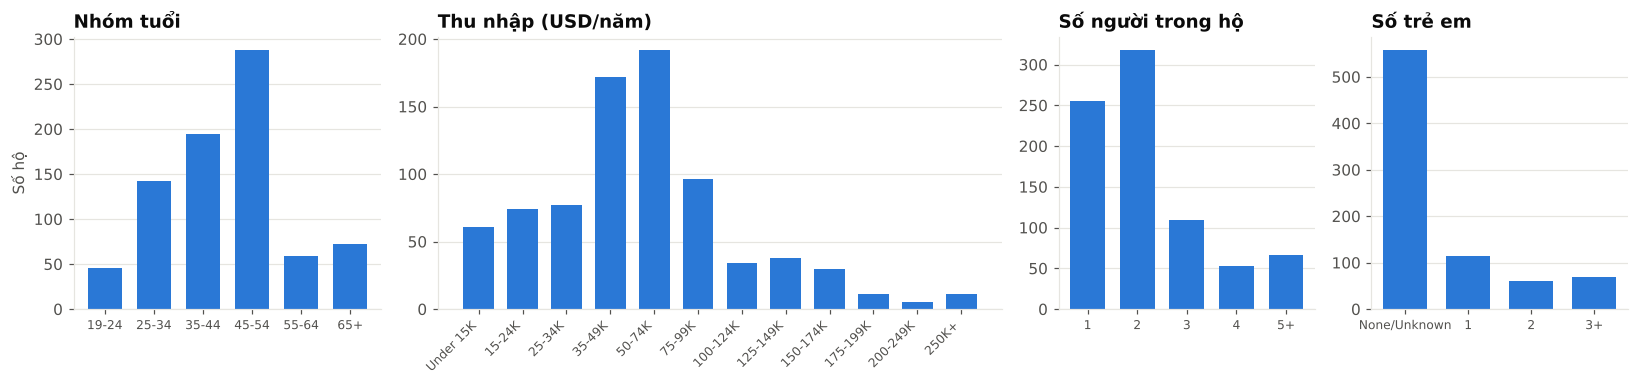

In [14]:
order = {'AGE_DESC':['19-24','25-34','35-44','45-54','55-64','65+'],
 'INCOME_DESC':['Under 15K','15-24K','25-34K','35-49K','50-74K','75-99K','100-124K','125-149K','150-174K','175-199K','200-249K','250K+'],
 'HOUSEHOLD_SIZE_DESC':['1','2','3','4','5+'], 'KID_CATEGORY_DESC':['None/Unknown','1','2','3+']}
titles = {'AGE_DESC':'Nhóm tuổi','INCOME_DESC':'Thu nhập (USD/năm)','HOUSEHOLD_SIZE_DESC':'Số người trong hộ','KID_CATEGORY_DESC':'Số trẻ em'}
fig, ax = plt.subplots(1,4, figsize=(15,3.6), gridspec_kw={'width_ratios':[1.2,2.2,1,1]})
for a,(col,o) in zip(ax,order.items()):
    v = demo[col].value_counts().reindex(o).fillna(0); a.bar(range(len(v)), v.values, color=BLUE, width=0.7)
    a.set_xticks(range(len(v))); a.set_xticklabels(o, rotation=45 if col=='INCOME_DESC' else 0, ha='right' if col=='INCOME_DESC' else 'center', fontsize=8)
    a.set(title=titles[col], ylabel='Số hộ' if col=='AGE_DESC' else ''); a.grid(axis='x', visible=False)
plt.tight_layout(); save(fig, 'H6_nhan_khau_hoc')

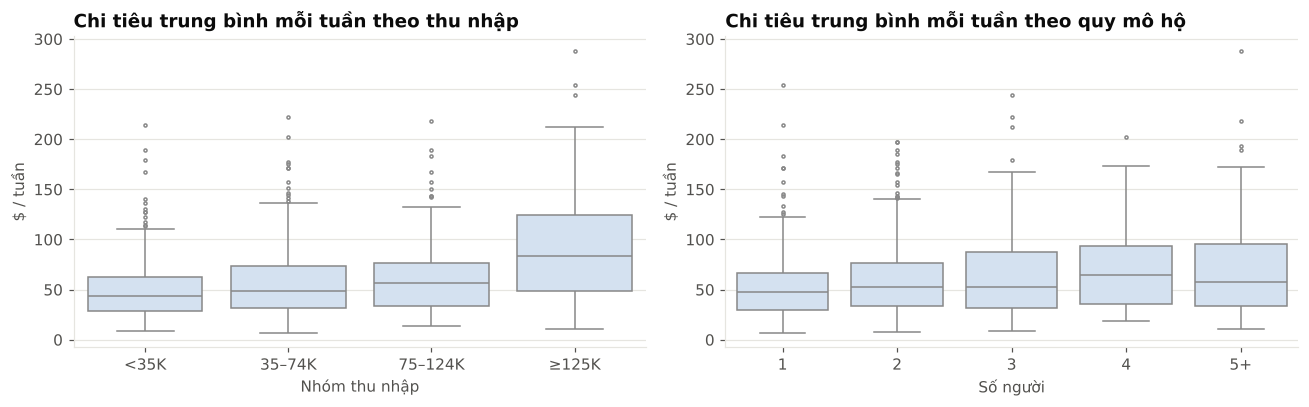

Trung vị chi tiêu tuần: có nhân khẩu học 51.7 | không có 15.6
{'<35K': 43.7, '35–74K': 48.3, '75–124K': 56.4, '≥125K': 83.9}


,Kiểm định,So sánh,Thống kê,p-value
0,Kruskal–Wallis,Chi tiêu tuần ~ nhóm thu nhập,4.517476e+01,8.494262e-10
1,Kruskal–Wallis,Chi tiêu tuần ~ quy mô hộ,1.286182e+01,1.197108e-02
2,Mann–Whitney U,Chi tiêu tuần: hộ có vs không có nhân khẩu học,1.156033e+06,1.950449e-175


In [15]:
d = demo.merge(hh[['weekly_spend']], left_on='household_key', right_index=True)
inc_grp = {'Under 15K':'<35K','15-24K':'<35K','25-34K':'<35K','35-49K':'35–74K','50-74K':'35–74K','75-99K':'75–124K','100-124K':'75–124K'}
d['inc3'] = d.INCOME_DESC.map(inc_grp).fillna('≥125K'); o3=['<35K','35–74K','75–124K','≥125K']
fig, ax = plt.subplots(1,2, figsize=(12,3.8))
sns.boxplot(data=d, x='inc3', y='weekly_spend', order=o3, color='#cfe0f5', fliersize=2, ax=ax[0], linewidth=1)
ax[0].set(title='Chi tiêu trung bình mỗi tuần theo thu nhập', xlabel='Nhóm thu nhập', ylabel='$ / tuần')
sns.boxplot(data=d, x='HOUSEHOLD_SIZE_DESC', y='weekly_spend', order=order['HOUSEHOLD_SIZE_DESC'], color='#cfe0f5', fliersize=2, ax=ax[1], linewidth=1)
ax[1].set(title='Chi tiêu trung bình mỗi tuần theo quy mô hộ', xlabel='Số người', ylabel='$ / tuần')
plt.tight_layout(); save(fig, 'H7_chi_tieu_theo_thu_nhap_quy_mo')
kw1 = stats.kruskal(*[g.weekly_spend for _,g in d.groupby('inc3')]); kw2 = stats.kruskal(*[g.weekly_spend for _,g in d.groupby('HOUSEHOLD_SIZE_DESC')])
has = hh.index.isin(demo.household_key); mw = stats.mannwhitneyu(hh.weekly_spend[has], hh.weekly_spend[~has])
tests = pd.DataFrame([
 ['Kruskal–Wallis','Chi tiêu tuần ~ nhóm thu nhập', kw1.statistic, kw1.pvalue],
 ['Kruskal–Wallis','Chi tiêu tuần ~ quy mô hộ', kw2.statistic, kw2.pvalue],
 ['Mann–Whitney U','Chi tiêu tuần: hộ có vs không có nhân khẩu học', mw.statistic, mw.pvalue]], columns=['Kiểm định','So sánh','Thống kê','p-value'])
print('Trung vị chi tiêu tuần: có nhân khẩu học', round(hh.weekly_spend[has].median(),1), '| không có', round(hh.weekly_spend[~has].median(),1))
print(d.groupby('inc3').weekly_spend.median().reindex(o3).round(1).to_dict())
tests.to_csv('../outputs/bang_kiem_dinh_eda.csv', index=False); tests

## 7. Chiến dịch, coupon và độ cân bằng biến mục tiêu

In [16]:
camp_hh = ctab.household_key.unique(); red_hh = red.household_key.unique()
y = pd.Series(np.isin(camp_hh, red_hh).astype(int), index=camp_hh)
pairs = ctab[['household_key','CAMPAIGN','DESCRIPTION']].drop_duplicates()
r2 = red[['household_key','CAMPAIGN']].drop_duplicates().assign(r=1)
pairs = pairs.merge(r2, how='left').fillna({'r':0})
bytype = pairs.groupby('DESCRIPTION').r.agg(['count','mean'])
print('Hộ nhận chiến dịch:', len(camp_hh), '| hộ dùng coupon:', y.sum(), f'({y.mean():.1%})')
print('Tỷ lệ dùng theo cặp hộ × chiến dịch:', round(pairs.r.mean(),3)); bytype

Hộ nhận chiến dịch: 1584 | hộ dùng coupon: 434 (27.4%)
Tỷ lệ dùng theo cặp hộ × chiến dịch: 0.123


,count,mean
DESCRIPTION,,
TypeA,3979,0.159588
TypeB,2655,0.079096
TypeC,574,0.076655


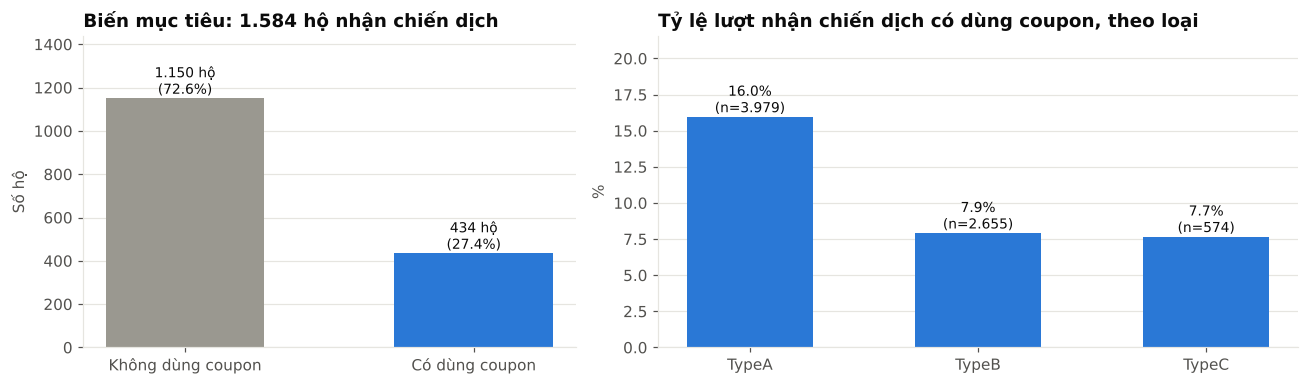

In [17]:
fig, ax = plt.subplots(1,2, figsize=(12,3.6), gridspec_kw={'width_ratios':[1,1.3]})
vals=[(y==0).sum(), (y==1).sum()]; ax[0].bar(['Không dùng coupon','Có dùng coupon'], vals, color=[GRAY, BLUE], width=0.55)
for i,v in enumerate(vals): ax[0].text(i, v, f'{vn(v)} hộ\n({v/sum(vals):.1%})', ha='center', va='bottom', fontsize=9, color=INK)
ax[0].set(title='Biến mục tiêu: 1.584 hộ nhận chiến dịch', ylabel='Số hộ', ylim=(0, max(vals)*1.25)); ax[0].grid(axis='x', visible=False)
b = bytype['mean']*100; ax[1].bar(b.index, b.values, color=BLUE, width=0.55)
for i,(k,v) in enumerate(b.items()): ax[1].text(i, v, f'{v:.1f}%\n(n={vn(bytype.loc[k,"count"])})', ha='center', va='bottom', fontsize=9, color=INK)
ax[1].set(title='Tỷ lệ lượt nhận chiến dịch có dùng coupon, theo loại', ylabel='%', ylim=(0, b.max()*1.35)); ax[1].grid(axis='x', visible=False)
plt.tight_layout(); save(fig, 'H8_can_bang_bien_muc_tieu')

In [18]:
# Cân bằng mẫu: nhân khẩu học trong nhóm nhận chiến dịch và tỷ lệ dùng coupon
has_d = np.isin(camp_hh, demo.household_key)
print('Có nhân khẩu học:', has_d.sum(), '/', len(camp_hh), '| tỷ lệ dùng coupon có/không:',
      round(y[has_d].mean(),3), round(y[~has_d].mean(),3))

Có nhân khẩu học: 760 / 1584 | tỷ lệ dùng coupon có/không: 0.409 0.149
